# ACLS CO2 Group Project - Air Quality Prediction

## Problem Description

Urban air quality is strongly influenced by the interaction between traffic emissions and meteorological conditions. Pollutants such as nitrogen dioxide ([NO₂](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/stickstoffdioxid.html)), ozone ([O₃](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/ozon.html)), and particulate matter ([PM₁₀](https://www.stadt-zuerich.ch/de/gesundheit/gesundheitsschutz/luftqualitaet/luftschadstoffe/feinstaub.html)) show temporal variability driven by traffic intensity and weather-dependent dispersion processes. These relationships are often non-linear and vary across time scales.

Air pollution affects the health of humans, animals, and ecosystems, contributing to respiratory and cardiovascular diseases and environmental stress even at [relatively low concentrations](https://www.who.int/health-topics/air-pollution#tab=tab_1). Although [air quality in Zurich](https://www.stadt-zuerich.ch/content/dam/web/de/aktuell/publikationen/2025/luftbilanz-2024.pdf) has improved significantly over recent decades and largely complies with current regulatory limits, [guidelines by the World Health Organisation from 2021](https://iris.who.int/items/5b0ca7ab-830a-44b8-b99f-4ee743b4d7b2) recommend substantially lower threshold values. This highlights the need for more detailed analyses that go beyond simple limit-value exceedances.

According to the [Open Government Data](https://data.stadt-zuerich.ch/) guidelines, the city of Zurich provides long-term, high-resolution data on air pollutants, meteorology, and traffic. This is very advantageous for machine learning applications. Furthermore, these models are well suited to capture complex interactions and temporal patterns. By comparing different modelling approaches, our project aims to assess their performance and to better understand the relative importance of traffic and meteorological drivers under present-day air quality conditions.

For this project we decided to work with three air pollutants (NO₂, O₃, PM₁₀) as dependent variables and meteorological and traffic data as independent variables. We compare two linear regression models (Lasso and Ridge), a KNN regression model, and a tree-based model (Random Forest Regressor). We will also compare two different time-encodings (Trigonometric and Spline) to see which one performs better. For each model, we will perform feature importance analysis and hyperparameter tuning. Eventually, we will compare the performance of all models (ensemble voting) and select the best one for each pollutant.
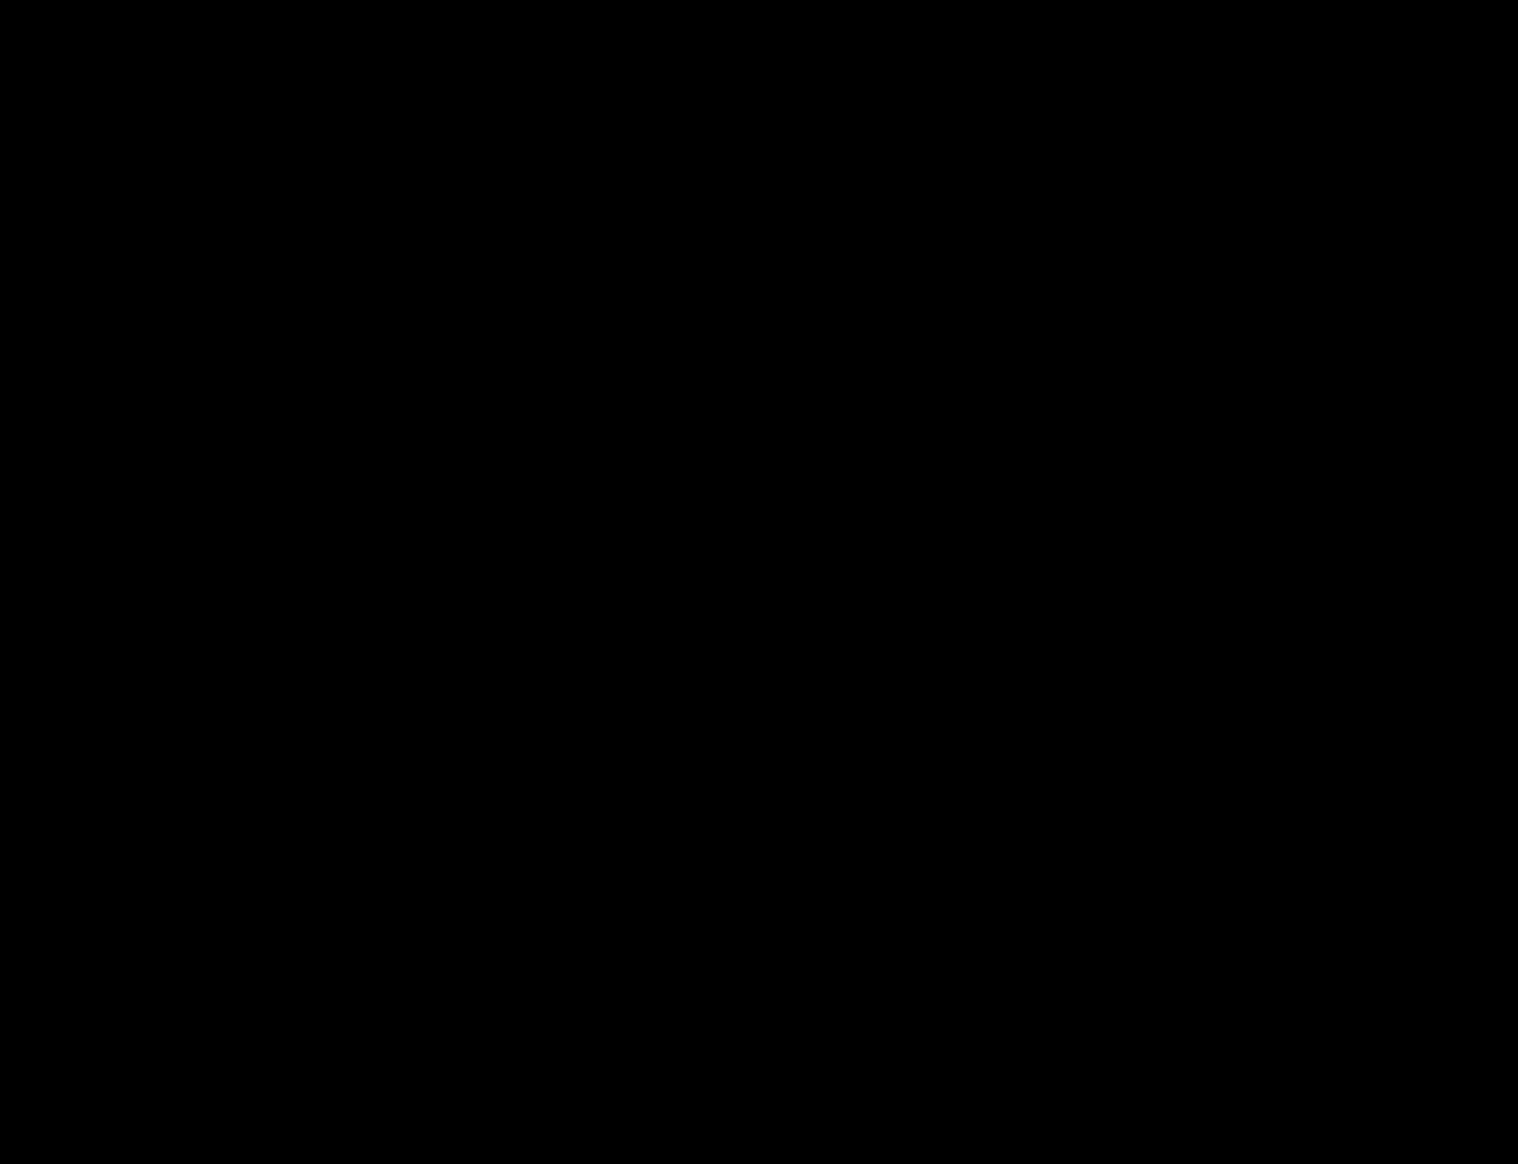
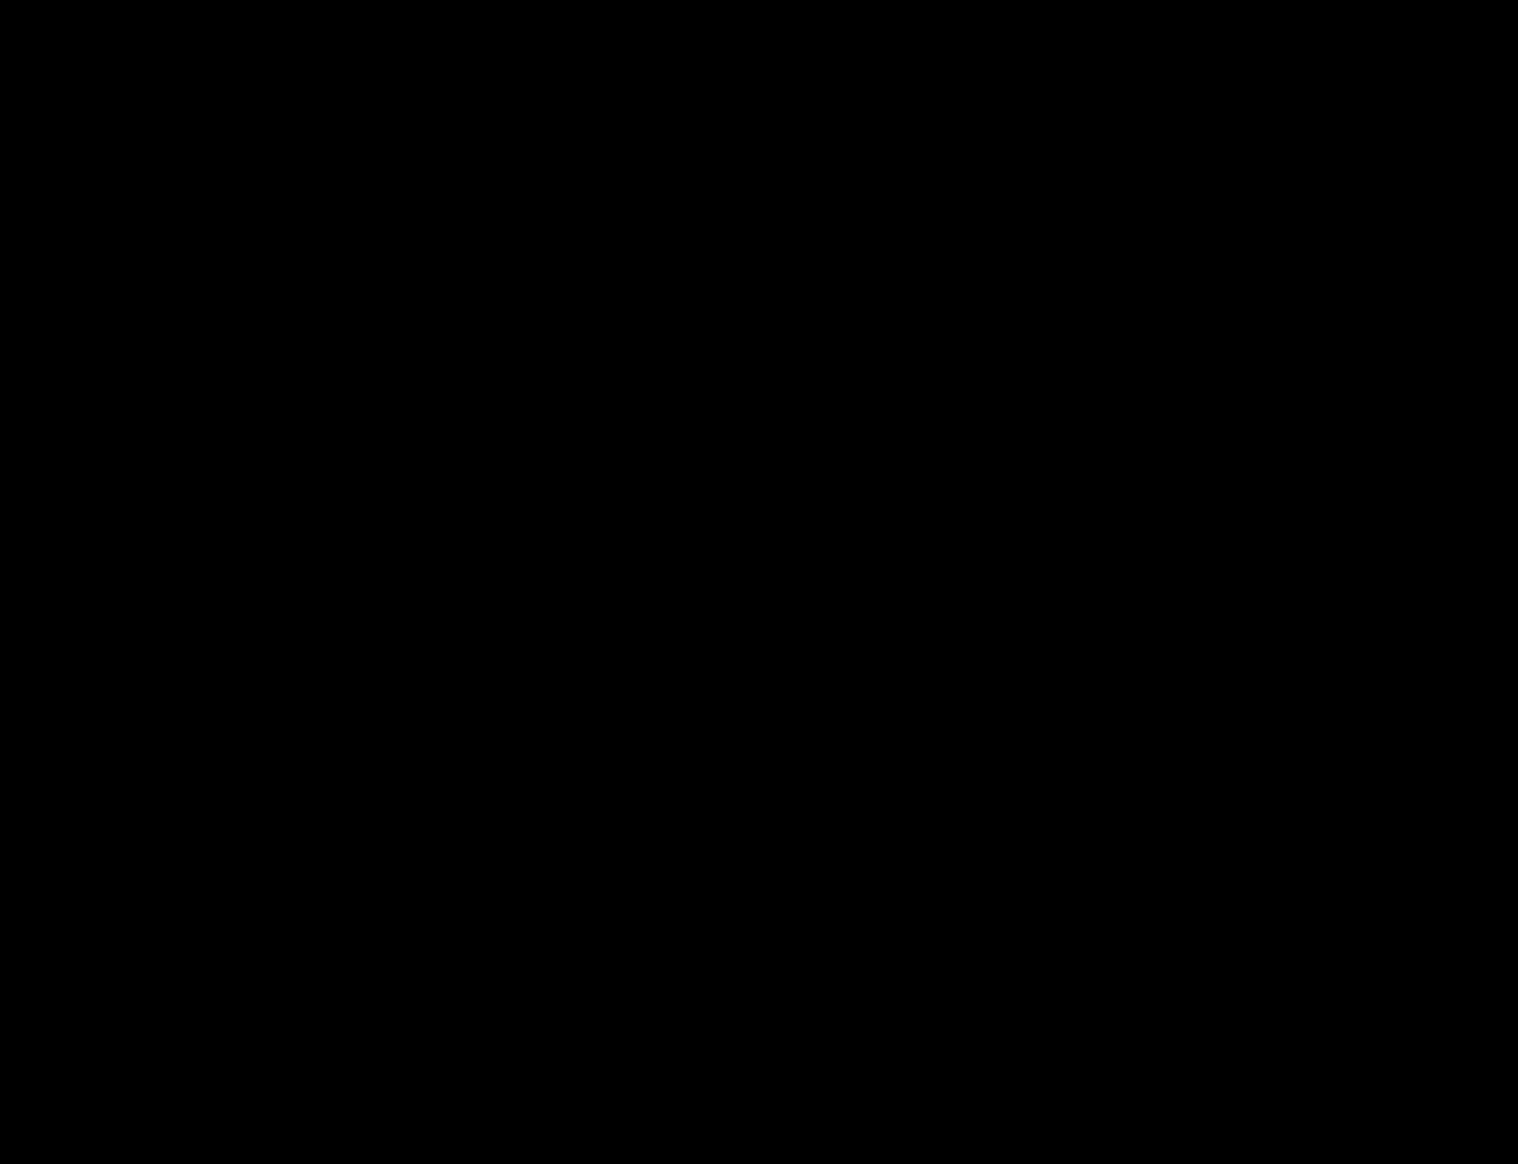

## Libraries

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn import preprocessing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from scipy.stats import randint
from sklearn.ensemble import VotingRegressor

## Import and Tidy Data

In [2]:
df_train_y = pd.read_csv('data/Datasets_MLready/y_train.csv')
df_train_y.head()

,NO2,O3,PM10
0,17.20,44.33,18.81
1,9.33,49.89,16.57
2,12.80,46.59,27.35
3,24.10,41.80,19.33
4,8.67,50.66,11.73


In [3]:
df_train_X = pd.read_csv('data/Datasets_MLready/X_train_transformed.csv')
df_train_X.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,encoded__Location_Zch_Rosengartenstrasse,encoded__Location_Zch_Schimmelstrasse,encoded__Location_Zch_Stampfenbachstrasse,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,1.0,0.0,0.0,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,1.0,0.0,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,0.0,1.0,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,1.0,0.0,0.0,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.0,1.0,0.0,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,2018.0


In [4]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols = list(df_train_X.filter(like="Spline_").columns)
scaled_cols = list(df_train_X.filter(like="scaled_").columns)
encoded_cols = list(df_train_X.filter(like="encoded_").columns)
year_col = list(df_train_X.filter(like="remainder_").columns)
tri_cols = list(df_train_X.iloc[:,0:8].columns)

In [239]:
# plotting a pairplot
# df_pairplot = df.drop(columns=["Datetime", "Month", "Weekday", "YearMonth"])
#
# sns.set_theme(style="ticks")
#
# sns.pairplot(df_pairplot, hue="Location")

In [240]:
# df[["Month", "Weekday", "Year"]] = df[["Month", "Weekday", "Year"]].astype("category")
#
# df.dtypes

## 3. Time-based cross-validation

In [5]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

## 4. Model Evaluation

In [77]:
# model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    print("%.2f ± %.2f" % (rmse.mean(), rmse.std()))

In [7]:
X_tri = df_train_X[encoded_cols + tri_cols + scaled_cols + year_col]
X_spl = df_train_X[encoded_cols + spline_cols + scaled_cols + year_col]

In [8]:
y_NO2 = df_train_y["NO2"]
y_O3 = df_train_y["O3"]
y_PM10 = df_train_y["PM10"]

In [245]:
df_train_y.describe()

,NO2,O3,PM10
count,171398.000000,171398.000000,171398.000000
mean,29.585936,45.986320,14.877335
std,17.374629,30.222047,9.619687
min,0.710000,-0.220000,-9.850000
25%,16.140000,21.350000,8.520000
50%,26.650000,44.960000,12.920000
75%,40.050000,66.140000,18.820000
max,308.120000,184.630000,593.440000


### Base Model Multiple Linear Regression

In [71]:
# Building linear regression model
model_base = LinearRegression()

print("linear regression, trigonometric encoding, NO2")
evaluate(model_base, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_base, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_base, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_base, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_base, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_base, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2


AttributeError: 'LinearRegression' object has no attribute 'items'

### Model 2 - Lasso

In [43]:
# Build and evaluate a basic model
alpha = 0.1
model_lasso = Lasso(alpha=alpha)

print("Lasso, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("Lasso, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("Lasso, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("Lasso, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("Lasso, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("Lasso, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

Lasso, trigonometric encoding, NO2
11.09 ± 3.55
Lasso, spline encoding, NO2
11.23 ± 3.41
Lasso, trigonometric encoding, O3
18.69 ± 3.38
Lasso, spline encoding, O3
18.29 ± 3.26
Lasso, trigonometric encoding, PM10
6.51 ± 0.73
Lasso, spline encoding, PM10
6.23 ± 0.33


### Model 3 - Ridge

In [44]:
# Build and evaluate a basic model
alpha = 0.1
model_ridge = Ridge(alpha=alpha)

print("Ridge, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("Ridge, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("Ridge, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("Ridge, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("Ridge, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("Ridge, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

Ridge, trigonometric encoding, NO2
11.09 ± 3.55
Ridge, spline encoding, NO2
11.23 ± 3.41
Ridge, trigonometric encoding, O3
18.69 ± 3.38
Ridge, spline encoding, O3
18.29 ± 3.26
Ridge, trigonometric encoding, PM10
6.51 ± 0.73
Ridge, spline encoding, PM10
6.23 ± 0.33


### Model 4 - KNN Regression

In [45]:
# Build and evaluate a basic model
n_neighbors = 15
model_KNN = KNeighborsRegressor(n_neighbors, weights="uniform")

print("KNN, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("KNN, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("KNN, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("KNN, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("KNN, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("KNN, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

KNN, trigonometric encoding, NO2
11.09 ± 3.55
KNN, spline encoding, NO2
11.23 ± 3.41
KNN, trigonometric encoding, O3
18.69 ± 3.38
KNN, spline encoding, O3
18.29 ± 3.26
KNN, trigonometric encoding, PM10
6.51 ± 0.73
KNN, spline encoding, PM10
6.23 ± 0.33


### Model 6 - Random Forest Regressor

In [33]:
# Build and evaluate a random forest model

model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,   # each tree sees 50% of rows
    n_jobs=-1,
    random_state=42
)

print("RF, trigonometric encoding, NO2")
evaluate(model_rf, X_tri, y_NO2)

print("RF, spline encoding, NO2")
evaluate(model_rf, X_spl, y_NO2)

print("RF, trigonometric encoding, O3")
evaluate(model_rf, X_tri, y_O3)

print("RF, spline encoding, O3")
evaluate(model_rf, X_spl, y_O3)

print("RF, trigonometric encoding, PM10")
evaluate(model_rf, X_tri, y_PM10)

print("RF, spline encoding, PM10")
evaluate(model_rf, X_spl, y_PM10)

RF, trigonometric encoding, NO2
10.33 ± 3.65
RF, spline encoding, NO2
10.44 ± 3.64
RF, trigonometric encoding, O3
17.58 ± 4.45
RF, spline encoding, O3
17.53 ± 4.48
RF, trigonometric encoding, PM10
7.15 ± 1.30
RF, spline encoding, PM10
7.14 ± 1.36


## 5. Feature selection

### Helper functions

In [34]:
# Build a grouping function
def group_features(feature_names):
    groups = {}
    for f in feature_names:
        # original variable name = prefix before first underscore
        base = f.split("__")[1].split("_")[0]
        groups.setdefault(base, []).append(f)
    return groups

# Compute grouped importance
def grouped_importance(model, X, y=None):
    # For Linear models
    if hasattr(model, "coef_"):
        raw = np.abs(model.coef_)
    # For Tree-based models
    elif hasattr(model, "feature_importances_"):
        raw = model.feature_importances_
    # Any other model without built-in importance
    else:
        if y is None:
            raise ValueError("y must be provided for models without built-in importance")
        # Sample from data, otherwise it is running very long
        X_sample = X.sample(5000, random_state=42)
        y_sample = y.loc[X_sample.index]
        permutation_result = permutation_importance(model, X_sample, y_sample, n_repeats=5, random_state=42)
        raw = permutation_result.importances_mean

    # Normalization
    normalized = raw / raw.sum()
    imp = pd.Series(normalized, index=X.columns)

    # Grouping
    groups = group_features(X.columns)
    grouped = {base: imp[cols].sum() for base, cols in groups.items()}

    return pd.Series(grouped).sort_values(ascending=False)

# Make grouped plots
def plot_grouped_importance_multi(
    plots,
    model_name,
    feature_order=None,
    figsize=(18, 6),
    sharey=True
):
    """
    Plot multiple grouped feature-importance comparisons (Trig vs Spline)
    in a single figure.

    Parameters
    ----------
    plots : list of dict
        Each dict must contain:
        {
            "tri_imp": pd.Series,
            "spl_imp": pd.Series,
            "feature_name": str
        }
    model_name : str
        Name of the model (used in titles).
    feature_order : list of str, optional
        Desired order of grouped features.
    figsize : tuple
        Figure size.
    sharey : bool
        Share y-axis across subplots.
    """

    if feature_order is None:
        feature_order = [
            "Year", "Month", "Weekday", "Time", "Day",
            "Location",
            "Hr", "RainDur", "T", "WVv", "StrGlo",
            "meanVehicles"
        ]

    n = len(plots)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=sharey)

    # Make axes iterable even if n == 1
    if n == 1:
        axes = [axes]

    for ax, p in zip(axes, plots):

        # Build grouped importance table
        df = pd.DataFrame({
            "Trig importance": p["tri_imp"],
            "Spline importance": p["spl_imp"]
        }).fillna(0)

        # Reorder and clean
        df = df.reindex(feature_order)
        df = df.dropna(how="all")

        if df.empty:
            ax.set_title(f'{p["feature_name"]} (no features)')
            ax.axis("off")
            continue

        df.plot(kind="bar", width=0.8, ax=ax)

        # Annotate bars
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

        ax.set_title(f'{model_name} - {p["feature_name"]}')
        ax.set_xlabel("Original Variable")
        ax.tick_params(axis="x", rotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha("right")

    axes[0].set_ylabel("Normalized Importance")
    fig.suptitle(f"{model_name} Feature Importance (Grouped)", y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()

### Model 2 - Lasso

#### Feature importance analysis

In [46]:
# Train the models for the individual datasets
alpha = 0.1

lasso_tri_NO2 = Lasso(alpha=alpha).fit(X_tri, y_NO2)
lasso_spl_NO2 = Lasso(alpha=alpha).fit(X_spl, y_NO2)

lasso_tri_O3 = Lasso(alpha=alpha).fit(X_tri, y_O3)
lasso_spl_O3 = Lasso(alpha=alpha).fit(X_spl, y_O3)

lasso_tri_PM10 = Lasso(alpha=alpha).fit(X_tri, y_PM10)
lasso_spl_PM10 = Lasso(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_lasso_tri_NO2 = grouped_importance(lasso_tri_NO2, X_tri)
g_imp_lasso_spl_NO2 = grouped_importance(lasso_spl_NO2, X_spl)

g_imp_lasso_tri_O3 = grouped_importance(lasso_tri_O3, X_tri)
g_imp_lasso_spl_O3 = grouped_importance(lasso_spl_O3, X_spl)

g_imp_lasso_tri_PM10 = grouped_importance(lasso_tri_PM10, X_tri)
g_imp_lasso_spl_PM10 = grouped_importance(lasso_spl_PM10, X_spl)

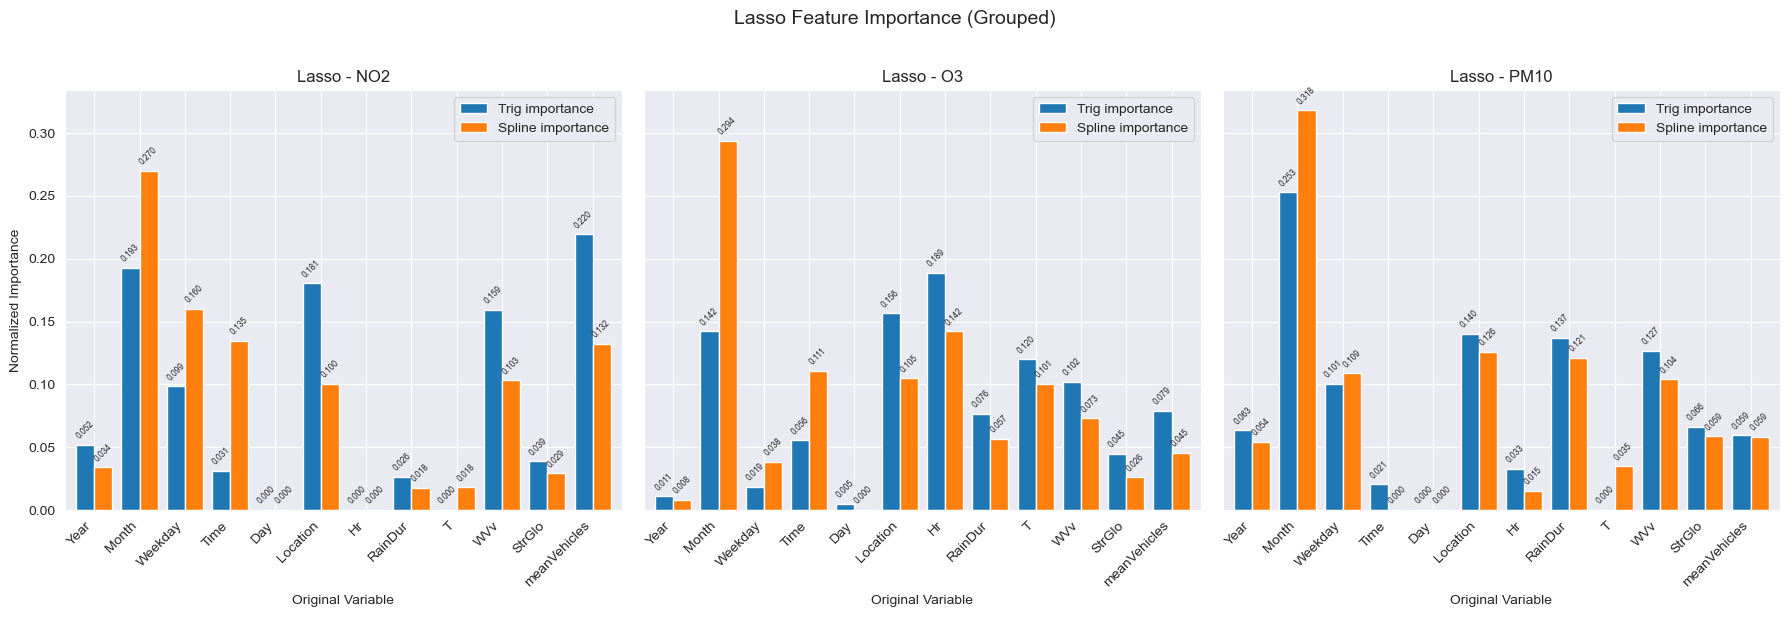

In [47]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_lasso_tri_NO2,  "spl_imp": g_imp_lasso_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_lasso_tri_O3,   "spl_imp": g_imp_lasso_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_lasso_tri_PM10, "spl_imp": g_imp_lasso_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Lasso"
)

#### Feature selection

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

### Model 3 - Ridge

#### Feature importance analysis

In [48]:
# Train the models for the individual datasets
alpha = 0.1

ridge_tri_NO2 = Ridge(alpha=alpha).fit(X_tri, y_NO2)
ridge_spl_NO2 = Ridge(alpha=alpha).fit(X_spl, y_NO2)

ridge_tri_O3 = Ridge(alpha=alpha).fit(X_tri, y_O3)
ridge_spl_O3 = Ridge(alpha=alpha).fit(X_spl, y_O3)

ridge_tri_PM10 = Ridge(alpha=alpha).fit(X_tri, y_PM10)
ridge_spl_PM10 = Ridge(alpha=alpha).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_ridge_tri_NO2 = grouped_importance(ridge_tri_NO2, X_tri)
g_imp_ridge_spl_NO2 = grouped_importance(ridge_spl_NO2, X_spl)

g_imp_ridge_tri_O3 = grouped_importance(ridge_tri_O3, X_tri)
g_imp_ridge_spl_O3 = grouped_importance(ridge_spl_O3, X_spl)

g_imp_ridge_tri_PM10 = grouped_importance(ridge_tri_PM10, X_tri)
g_imp_ridge_spl_PM10 = grouped_importance(ridge_spl_PM10, X_spl)

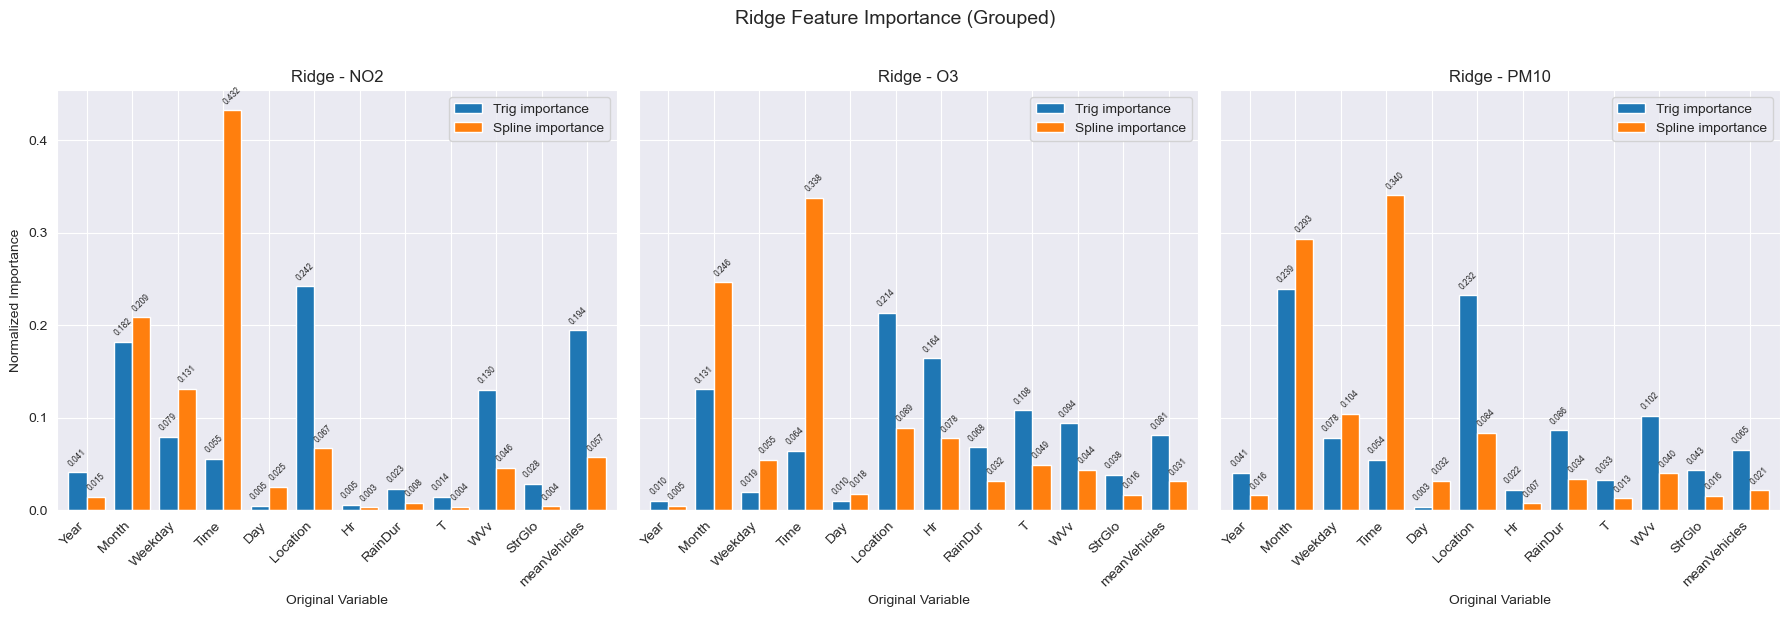

In [49]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_ridge_tri_NO2,  "spl_imp": g_imp_ridge_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_ridge_tri_O3,   "spl_imp": g_imp_ridge_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_ridge_tri_PM10, "spl_imp": g_imp_ridge_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Ridge"
)

#### Feature selection

No weather or traffic feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

### Model 4 - KNN Regression

#### Feature importance analysis

In [50]:
# Train the models for the individual datasets
n_neighbors = 15

KNN_tri_NO2 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_NO2)
KNN_spl_NO2 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_NO2)

KNN_tri_O3 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_O3)
KNN_spl_O3 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_O3)

KNN_tri_PM10 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_tri, y_PM10)
KNN_spl_PM10 = KNeighborsRegressor(n_neighbors, weights="uniform").fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_KNN_tri_NO2 = grouped_importance(KNN_tri_NO2, X_tri, y_NO2)
g_imp_KNN_spl_NO2 = grouped_importance(KNN_spl_NO2, X_spl, y_NO2)

g_imp_KNN_tri_O3 = grouped_importance(KNN_tri_O3, X_tri, y_O3)
g_imp_KNN_spl_O3 = grouped_importance(KNN_spl_O3, X_spl, y_O3)

g_imp_KNN_tri_PM10 = grouped_importance(KNN_tri_PM10, X_tri, y_PM10)
g_imp_KNN_spl_PM10 = grouped_importance(KNN_spl_PM10, X_spl, y_PM10)

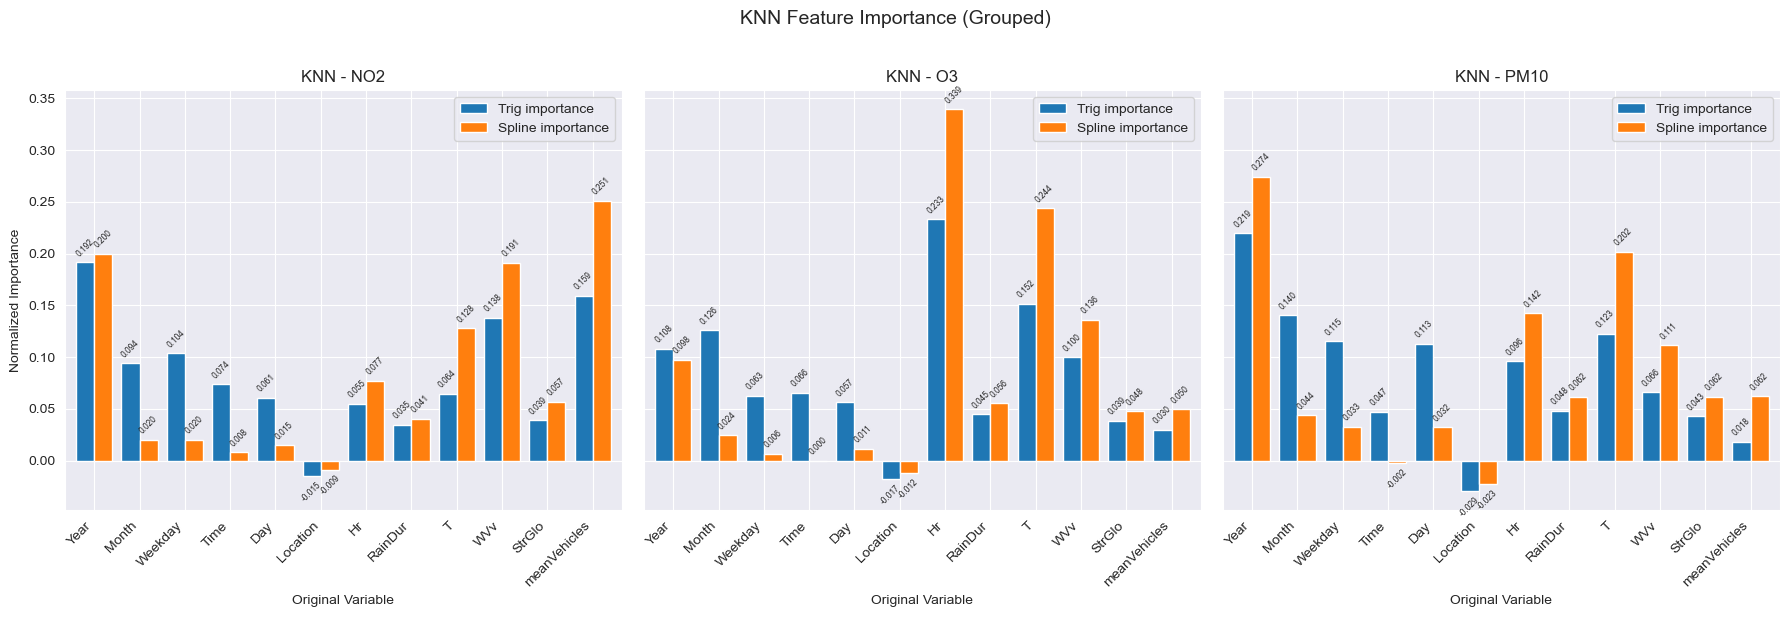

In [51]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_KNN_tri_NO2,  "spl_imp": g_imp_KNN_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_KNN_tri_O3,   "spl_imp": g_imp_KNN_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_KNN_tri_PM10, "spl_imp": g_imp_KNN_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="KNN"
)

#### Feature selection

Since Location feature shows negative value on the KNN Regressor performace, we will drop it from the X datasets for this model.

In [52]:
X_tri_KNN = X_tri.drop(["encoded__Location_Zch_Rosengartenstrasse", "encoded__Location_Zch_Schimmelstrasse", "encoded__Location_Zch_Stampfenbachstrasse"], axis="columns")
X_spl_KNN = X_spl.drop(["encoded__Location_Zch_Rosengartenstrasse", "encoded__Location_Zch_Schimmelstrasse", "encoded__Location_Zch_Stampfenbachstrasse"], axis="columns")

### Model 5 - Random Forest Regressor

#### Feature importance analysis

In [35]:
RF_tri_NO2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_NO2)

RF_spl_NO2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_NO2)

RF_tri_O3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_O3)

RF_spl_O3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_O3)

RF_tri_PM10 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_tri, y_PM10)

RF_spl_PM10 = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
).fit(X_spl, y_PM10)

# Build grouped importance tables for all 6 models
g_imp_RF_tri_NO2 = grouped_importance(RF_tri_NO2, X_tri, y_NO2)
g_imp_RF_spl_NO2 = grouped_importance(RF_spl_NO2, X_spl, y_NO2)

g_imp_RF_tri_O3 = grouped_importance(RF_tri_O3, X_tri, y_O3)
g_imp_RF_spl_O3 = grouped_importance(RF_spl_O3, X_spl, y_O3)

g_imp_RF_tri_PM10 = grouped_importance(RF_tri_PM10, X_tri, y_PM10)
g_imp_RF_spl_PM10 = grouped_importance(RF_spl_PM10, X_spl, y_PM10)

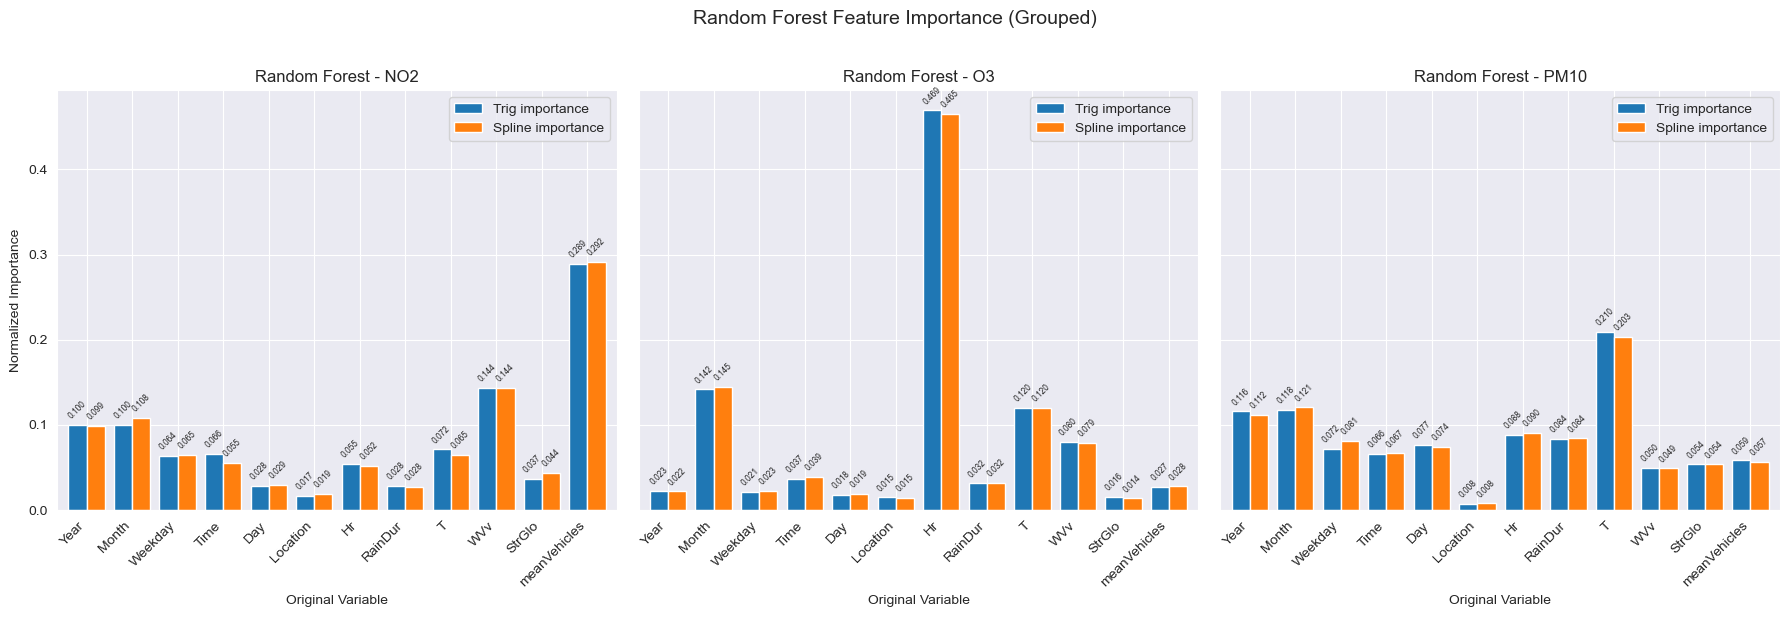

In [36]:
# Plot the grouped importance
plots = [
    {"tri_imp": g_imp_RF_tri_NO2,  "spl_imp": g_imp_RF_spl_NO2,  "feature_name": "NO2"},
    {"tri_imp": g_imp_RF_tri_O3,   "spl_imp": g_imp_RF_spl_O3,   "feature_name": "O3"},
    {"tri_imp": g_imp_RF_tri_PM10, "spl_imp": g_imp_RF_spl_PM10, "feature_name": "PM10"},
]

plot_grouped_importance_multi(
    plots,
    model_name="Random Forest"
)

The feature importance plot for NO2 and PM10 is comparable. Interestingly, the mean number of vehicles shows a lower influence on PM10 than for NO2 (for which it represents the highest influence). Year, Month and T (temperature) show the highest importance for PM10.
Hr (relative humidity), Month, T, and WVv (vector wind speed) have the highest influence on O3.

#### Feature selection

We will continue with all the features.

## 6. Hyperparameter Tuning

### Model 2 - Lasso

In [53]:
# Find all hyperparams of the model
Lasso().get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 1000,
 'positive': False,
 'precompute': False,
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'warm_start': False}

Since Lasso model contains only few hyperparameters to tune, we will use Grid search

In [54]:
# Use a full grid over hyperparameters with a helper function
def tune_lasso(X, y, tss):
    """
    Run hyperparameter tuning for a single Lasso model using TimeSeriesSplit.
    """
    model = Lasso()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_lasso_tri_NO2 = tune_lasso(X_tri, y_NO2, tss)
tuned_lasso_spl_NO2 = tune_lasso(X_spl, y_NO2, tss)

tuned_lasso_tri_O3 = tune_lasso(X_tri, y_O3, tss)
tuned_lasso_spl_O3 = tune_lasso(X_spl, y_O3, tss)

tuned_lasso_tri_PM10 = tune_lasso(X_tri, y_PM10, tss)
tuned_lasso_spl_PM10 = tune_lasso(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_lasso_models = [
    ("NO2 - Trig", tuned_lasso_tri_NO2),
    ("NO2 - Spline", tuned_lasso_spl_NO2),
    ("O3 - Trig", tuned_lasso_tri_O3),
    ("O3 - Spline", tuned_lasso_spl_O3),
    ("PM10 - Trig", tuned_lasso_tri_PM10),
    ("PM10 - Spline", tuned_lasso_spl_PM10)
]

# Summarize result
for name, model in tuned_lasso_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.089663003547487
Best Hyperparameters: {'alpha': 0.1, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 - Spline
Best Score: -10.904957652670957
Best Hyperparameters: {'alpha': 0.01, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Trig
Best Score: -17.453407661931585
Best Hyperparameters: {'alpha': 1, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Spline
Best Score: -17.273447150222953
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 - Trig
Best Score: -6.2093176156536245
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 - Spline
Best Score: -6.180739875628598
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}



### Model 3 - Ridge

In [55]:
# Find all hyperparams of the model
Ridge().get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': None,
 'positive': False,
 'random_state': None,
 'solver': 'auto',
 'tol': 0.0001}

Since Ridge model contains only few hyperparameters to tune, we will use Grid search

In [56]:
# Use a full grid over hyperparameters with a helper function
def tune_ridge(X, y, tss):
    """
    Run hyperparameter tuning for a single Ridge model using TimeSeriesSplit.
    """
    model = Ridge()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_ridge_tri_NO2 = tune_ridge(X_tri, y_NO2, tss)
tuned_ridge_spl_NO2 = tune_ridge(X_spl, y_NO2, tss)

tuned_ridge_tri_O3 = tune_ridge(X_tri, y_O3, tss)
tuned_ridge_spl_O3 = tune_ridge(X_spl, y_O3, tss)

tuned_ridge_tri_PM10 = tune_ridge(X_tri, y_PM10, tss)
tuned_ridge_spl_PM10 = tune_ridge(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_ridge_models = [
    ("NO2 - Trig", tuned_ridge_tri_NO2),
    ("NO2 - Spline", tuned_ridge_spl_NO2),
    ("O3 - Trig", tuned_ridge_tri_O3),
    ("O3 - Spline", tuned_ridge_spl_O3),
    ("PM10 - Trig", tuned_ridge_tri_PM10),
    ("PM10 - Spline", tuned_ridge_spl_PM10)
]

# Summarize result
for name, model in tuned_ridge_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.149539549911704
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 - Spline
Best Score: -10.892325542540096
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Trig
Best Score: -19.101650713025492
Best Hyperparameters: {'alpha': 10, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 - Spline
Best Score: -18.06332775751101
Best Hyperparameters: {'alpha': 1, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 - Trig
Best Score: -6.6744312045239145
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}

Model: PM10 - Spline
Best Score: -6.451579553539455
Best Hyperparameters: {'alpha': 10, 'fit_intercept': False, 'max_iter': 5000}



### Model 4 - KNN Regression

In [57]:
# Find all hyperparams of the model
KNeighborsRegressor().get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

Since KNN Regression model contains more hyperparameters to tune, we will use Randomized search.

In [58]:
# Use a randomized grid over hyperparameters with a helper function
def tune_KNN(X, y, tss):
    """
    Run hyperparameter tuning for a single KNN Regression model using TimeSeriesSplit.
    """
    model = KNeighborsRegressor()

    param_grid = {
        "n_neighbors": [20, 25, 30, 35, 40, 100],
        "weights": ["uniform", "distance"],
        "metric": ["minkowski"],
        "p": [1, 2],
    }

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=20,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_KNN_tri_NO2 = tune_KNN(X_tri, y_NO2, tss)
tuned_KNN_spl_NO2 = tune_KNN(X_spl, y_NO2, tss)

tuned_KNN_tri_O3 = tune_KNN(X_tri, y_O3, tss)
tuned_KNN_spl_O3 = tune_KNN(X_spl, y_O3, tss)

tuned_KNN_tri_PM10 = tune_KNN(X_tri, y_PM10, tss)
tuned_KNN_spl_PM10 = tune_KNN(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_KNN_models = [
    ("NO2 - Trig", tuned_KNN_tri_NO2),
    ("NO2 - Spline", tuned_KNN_spl_NO2),
    ("O3 - Trig", tuned_KNN_tri_O3),
    ("O3 - Spline", tuned_KNN_spl_O3),
    ("PM10 - Trig", tuned_KNN_tri_PM10),
    ("PM10 - Spline", tuned_KNN_spl_PM10)
]

# Summarize result
for name, model in tuned_KNN_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -11.233086385503025
Best Hyperparameters: {'weights': 'uniform', 'p': 2, 'n_neighbors': 40, 'metric': 'minkowski'}

Model: NO2 - Spline
Best Score: -11.017791854482207
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 30, 'metric': 'minkowski'}

Model: O3 - Trig
Best Score: -17.938460904496065
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: O3 - Spline
Best Score: -16.57801135752809
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: PM10 - Trig
Best Score: -6.211865515104399
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}

Model: PM10 - Spline
Best Score: -5.9965888801665965
Best Hyperparameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 100, 'metric': 'minkowski'}



### Model 5 - Random Forest Regressor

In [37]:
# Find all hyperparams of the model
RandomForestRegressor().get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Since Random Forest Regression model contains more hyperparameters to tune, we will use Randomized search.

In [40]:
# Use a randomized grid over hyperparameters with a helper function
def tune_RF(X, y, tss):
    """
    Run hyperparameter tuning for a single KNN Regression model using TimeSeriesSplit.
    """
    model = RandomForestRegressor()

    param_grid = {
        "max_depth": [10, 15, 20, None],
        "min_samples_leaf": randint(1, 21),
        "min_samples_split": randint(2, 41),
        "max_features": ["sqrt", 0.5, 0.8],
    }

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=20,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_RF_tri_NO2 = tune_RF(X_tri, y_NO2, tss)
tuned_RF_spl_NO2 = tune_RF(X_spl, y_NO2, tss)

tuned_RF_tri_O3 = tune_RF(X_tri, y_O3, tss)
tuned_RF_spl_O3 = tune_RF(X_spl, y_O3, tss)

tuned_RF_tri_PM10 = tune_RF(X_tri, y_PM10, tss)
tuned_RF_spl_PM10 = tune_RF(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_RF_models = [
    ("NO2 - Trig", tuned_RF_tri_NO2),
    ("NO2 - Spline", tuned_RF_spl_NO2),
    ("O3 - Trig", tuned_RF_tri_O3),
    ("O3 - Spline", tuned_RF_spl_O3),
    ("PM10 - Trig", tuned_RF_tri_PM10),
    ("PM10 - Spline", tuned_RF_spl_PM10)
]

# Summarize result
for name, model in tuned_RF_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 - Trig
Best Score: -10.332892083179328
Best Hyperparameters: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 7, 'min_samples_split': 23}

Model: NO2 - Spline
Best Score: -10.467642568058794
Best Hyperparameters: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 9, 'min_samples_split': 5}

Model: O3 - Trig
Best Score: -16.71668365017711
Best Hyperparameters: {'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 19, 'min_samples_split': 8}

Model: O3 - Spline
Best Score: -16.962868007722065
Best Hyperparameters: {'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 18, 'min_samples_split': 40}

Model: PM10 - Trig
Best Score: -6.510041105823555
Best Hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 12, 'min_samples_split': 16}

Model: PM10 - Spline
Best Score: -6.7442047183054274
Best Hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'min_samples_split': 27}



## 6.2 Model evaluation 02

### Model 2 - Lasso

In [260]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_lasso_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_lasso_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_lasso_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_lasso_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_lasso_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_lasso_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.09 ± 3.55
NO2 – Spline RMSE is: 10.90 ± 3.46
O3 – Trig RMSE is: 17.45 ± 4.46
O3 – Spline RMSE is: 17.27 ± 4.19
PM10 – Trig RMSE is: 6.21 ± 0.28
PM10 – Spline RMSE is: 6.18 ± 0.27


Using Lasso model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy and also highest variability.

### Model 3 - Ridge

In [261]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_ridge_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_ridge_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_ridge_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_ridge_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_ridge_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_ridge_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.15 ± 3.46
NO2 – Spline RMSE is: 10.89 ± 3.44
O3 – Trig RMSE is: 19.10 ± 3.28
O3 – Spline RMSE is: 18.06 ± 3.29
PM10 – Trig RMSE is: 6.67 ± 1.33
PM10 – Spline RMSE is: 6.45 ± 1.00


Using Ridge model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy, while NO2 prediction shows the highest variability.

### Model 4 - KNN Regression

In [304]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_KNN_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_KNN_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_KNN_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_KNN_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_KNN_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_KNN_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 – Trig RMSE is: 11.20 ± 3.72
NO2 – Spline RMSE is: 11.02 ± 3.72
O3 – Trig RMSE is: 17.94 ± 4.65
O3 – Spline RMSE is: 16.58 ± 3.64
PM10 – Trig RMSE is: 6.21 ± 1.15
PM10 – Spline RMSE is: 6.00 ± 0.69


Using KNN Ridge Regression model, Spline encoding gives consistently, but only slightly better results. Out of the 3 pollutants, O3 is predicted with least accuracy and also shows the highest variability.

### Model 5 - Random Forest Regressor

In [41]:
# Evaluate models with tuned hyperparameters
# Put them in a list for easy print
evaluation_jobs = [
    ("NO2 - Trig", tuned_RF_tri_NO2.best_estimator_, X_tri, y_NO2),
    ("NO2 - Spline", tuned_RF_spl_NO2.best_estimator_, X_spl, y_NO2),
    ("O3 - Trig", tuned_RF_tri_O3.best_estimator_, X_tri, y_O3),
    ("O3 - Spline", tuned_RF_spl_O3.best_estimator_, X_spl, y_O3),
    ("PM10 - Trig", tuned_RF_tri_PM10.best_estimator_, X_tri, y_PM10),
    ("PM10 - Spline", tuned_RF_spl_PM10.best_estimator_, X_spl, y_PM10)
]

for name, model, X, y in evaluation_jobs:
    print(f"{name} RMSE is: ", end="")
    evaluate(model, X, y)

NO2 - Trig RMSE is: 10.40 ± 3.59
NO2 - Spline RMSE is: 10.50 ± 3.64
O3 - Trig RMSE is: 16.91 ± 3.91
O3 - Spline RMSE is: 16.95 ± 4.19
PM10 - Trig RMSE is: 6.52 ± 1.25
PM10 - Spline RMSE is: 6.82 ± 1.44


dfgg

## 7. Model Evaluation Metrics

averaged across CV splits during model selection
reported on the final test year (2025)
- RMSE
- MAE

## 8. Model Selection

### Ensemble with Voting

In [74]:
best_Lasso_NO2 = tuned_lasso_spl_NO2.best_estimator_
best_Ridge_NO2 = tuned_ridge_spl_NO2.best_estimator_
best_KNN_NO2 = tuned_KNN_spl_NO2.best_estimator_
best_rf_NO2 = tuned_RF_tri_NO2.best_estimator_

best_Lasso_O3 = tuned_lasso_spl_O3.best_estimator_
best_Ridge_O3 = tuned_ridge_spl_O3.best_estimator_
best_KNN_O3 = tuned_KNN_spl_O3.best_estimator_
best_rf_O3 = tuned_RF_tri_O3.best_estimator_

best_Lasso_PM10 = tuned_lasso_spl_PM10.best_estimator_
best_Ridge_PM10 = tuned_ridge_spl_PM10.best_estimator_
best_KNN_PM10 = tuned_KNN_spl_PM10.best_estimator_
best_rf_PM10 = tuned_RF_tri_PM10.best_estimator_

In [78]:
voting_reg = VotingRegressor(
    estimators=[
        ("Ridge", best_Ridge_NO2),
        ("Lasso", best_Lasso_NO2),
        ("KNN", best_KNN_NO2),
        ("Random Forest", best_rf_NO2)
    ]
)

print("Ensemble, trigonometric encoding, NO2")
evaluate(voting_reg, X_tri, y_NO2)
print("Ensemble, spline encoding, NO2")
evaluate(voting_reg, X_spl, y_NO2)

print("Ensemble, trigonometric encoding, O3")
evaluate(voting_reg, X_tri, y_O3)
print("Ensemble, spline encoding, O3")
evaluate(voting_reg, X_spl, y_O3)

print("Ensemble, trigonometric encoding, PM10")
evaluate(voting_reg, X_tri, y_PM10)
print("Ensemble, spline encoding, PM10")
evaluate(voting_reg, X_spl, y_PM10)

Ensemble, trigonometric encoding, NO2
10.65 ± 3.63
Ensemble, spline encoding, NO2
10.56 ± 3.62
Ensemble, trigonometric encoding, O3
17.26 ± 3.96
Ensemble, spline encoding, O3
16.76 ± 3.79
Ensemble, trigonometric encoding, PM10
6.27 ± 0.93
Ensemble, spline encoding, PM10
6.15 ± 0.85


2️⃣ What improvement (or no improvement) means
✅ If the ensemble performs better than all single models

This tells you:

error patterns are weakly correlated

different models capture complementary structure

the system is complex and multi-regime

In air pollution terms:

traffic dominates at some times

meteorology dominates at others

linear models fail in some regimes, trees in others

⚠️ If the ensemble is similar to the best model

This tells you:

one model already captures most structure

other models add little independent information

the system is comparatively well-behaved

In this case, the ensemble adds robustness, not insight.

❌ If the ensemble is worse

This tells you:

some models are systematically bad

error correlation is high

averaging dilutes strong signals

This often happens if:

kNN struggles with high dimensionality

linear models miss strong nonlinearities

4️⃣ How to interpret ensemble results in your study

A correct interpretation paragraph could be:

“The ensemble model consistently outperformed individual models, indicating that linear, nonlinear, and local modelling approaches capture complementary aspects of the relationship between air pollutants, traffic, and meteorological conditions. This suggests that urban air pollution dynamics in Zurich cannot be fully represented by a single modelling paradigm.”

If it does not outperform:

“The ensemble performance was comparable to that of the best individual model, indicating that a single modelling approach already captured the dominant structure in the data.”

Compare all models (e.g. linear regression, random forest, ...)

- Mean CV RMSE
- Stability across folds (standard deviation)
- Interpretability
- Computational complexity

## 9. Final Training and Testing

With the best model only, not all of them

- The selected model is refit on all training data (2018–2024)
- Predictions are generated for 2025
- Final performance is reported on the test set